# Data analysis

In [16]:
from astroquery.simbad import Simbad

q = ("SELECT main_id, pmra, pmdec FROM basic JOIN ident ON oidref = oid "
     "WHERE id = 'NAME Barnard''s star' OR id = '* Barnard''s star'")
try:
    print(Simbad.query_tap(q))
except Exception as e:
    print(type(e).__name__, "->", str(e)[:500])

      main_id         pmra     pmdec  
                    mas / yr  mas / yr
------------------- -------- ---------
NAME Barnard's star -801.551 10362.394


In [15]:
from astroquery.simbad import Simbad
from api.targets import TARGETS

names = {"barnards-star": "* Barnard's star", "wise-0855-0714": "WISE J085510.83-071442.5",
         "eps-ind-b": "* eps Ind B", "rw-aurigae": "* RW Aur", "r-draconis": "* R Dra"}
for k, n in names.items():
    q = f"SELECT main_id, pmra, pmdec FROM basic JOIN ident ON oidref = oid WHERE id = '{n}'"
    try:
        r = Simbad.query_tap(q)
        print(k, "SIMBAD:", list(r[0]) if len(r) else "not found", "| targets.py:", TARGETS[k]["pmra"], TARGETS[k]["pmdec"])
    except Exception as e:
        print(k, "failed:", type(e).__name__); break

barnards-star failed: ValueError


In [17]:
# Gaia DR3 via VizieR (a different server from SIMBAD)
from astroquery.vizier import Vizier
from astropy.coordinates import SkyCoord
import astropy.units as u
from api.targets import TARGETS

v = Vizier(columns=["Source", "RA_ICRS", "DE_ICRS", "pmRA", "pmDE", "Gmag"], row_limit=10)
for k in ["barnards-star", "eps-ind-b"]:
    t = TARGETS[k]
    c = SkyCoord(t["ra"], t["dec"], unit="deg")
    try:
        res = v.query_region(c, radius=6 * u.arcmin, catalog="I/355/gaiadr3")
        tab = res[0] if len(res) else None
        print(k, "targets.py:", t["pmra"], t["pmdec"])
        if tab is not None:
            tab.sort("Gmag"); print(tab[:3])
        else:
            print("  no match")
    except Exception as e:
        print(k, "failed:", type(e).__name__, str(e)[:300])

barnards-star failed: HTTPError 404 Client Error: Not Found for url: https://vizier.cds.unistra.fr/viz-bin/votable
eps-ind-b failed: HTTPError 404 Client Error: Not Found for url: https://vizier.cds.unistra.fr/viz-bin/votable


In [18]:
from astroquery.simbad import Simbad
from api.targets import TARGETS

cands = {
    "wise-0855-0714": ["WISE J085510.83-071442.5", "WISE 0855-0714", "NAME WISE 0855-0714"],
    "eps-ind-b":      ["* eps Ind B", "eps Ind B", "* eps Ind Ba", "* eps Ind Bab"],
    "rw-aurigae":     ["* RW Aur", "RW Aur", "V* RW Aur"],
    "r-draconis":     ["V* R Dra", "* R Dra", "R Dra"],
}
for k, names in cands.items():
    t, hit = TARGETS[k], None
    for n in names:
        n = n.replace("'", "''")
        r = Simbad.query_tap(f"SELECT main_id, pmra, pmdec FROM basic JOIN ident ON oidref = oid WHERE id = '{n}'")
        if len(r):
            hit = r[0]; break
    print(k, "| SIMBAD:", (hit["main_id"], hit["pmra"], hit["pmdec"]) if hit is not None else "not found",
          "| targets.py:", t["pmra"], t["pmdec"])

wise-0855-0714 | SIMBAD: ('WISEA J085510.74-071442.5', np.float64(-8123.7), np.float64(673.2)) | targets.py: -8118.0 -681.0
eps-ind-b | SIMBAD: ('* eps Ind B', np.float64(3981.977), np.float64(-2466.832)) | targets.py: 3966.0 -2536.0
rw-aurigae | SIMBAD: ('V* RW Aur', np.float64(7.23), np.float64(-20.33)) | targets.py: 0.0 0.0
r-draconis | SIMBAD: ('V* R Dra', np.float64(-20.643), np.float64(6.149)) | targets.py: 0.0 0.0


3 frames: [(17, 60902.865380738), (24, 61118.309897451), (17, 61268.631477786)]


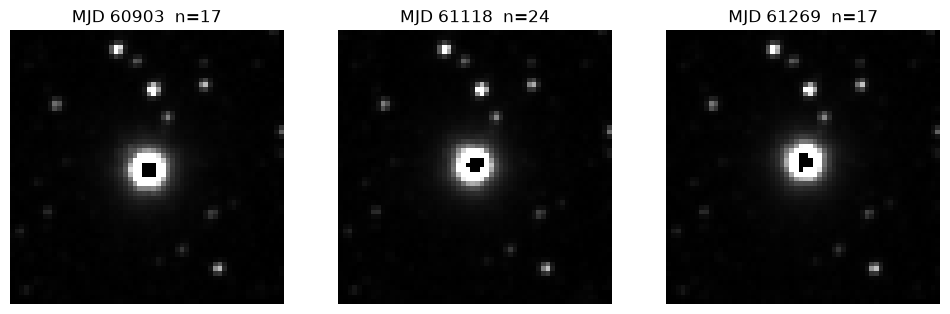

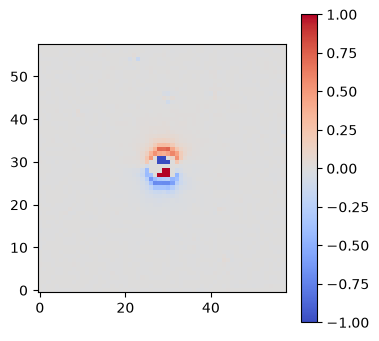

In [19]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "science" else Path.cwd()))

from api.load_cache import load_cutouts
from api.targets import TARGETS
from science.pipeline import build_frames, difference
import matplotlib.pyplot as plt

key = "barnards-star"           # or "fake_mover", "wise-0855-0714", ...
t = TARGETS[key]
cuts = load_cutouts(key)
cuts = [c for c in cuts if c.detector == 6]     # build_frames has no detector argument: pass one detector

frames = build_frames(cuts, t["ra"], t["dec"], fov_arcmin=6.0)
print(len(frames), "frames:", [(f.n_images, f.mjd_start) for f in frames])

fig, ax = plt.subplots(1, len(frames), figsize=(4 * len(frames), 4))
for a, f in zip(ax, frames):
    a.imshow(f.image, origin="lower", cmap="gray"); a.set_title(f"MJD {f.mjd_start:.0f}  n={f.n_images}"); a.axis("off")

d = difference(frames[0], frames[-1])           # later - earlier
plt.figure(figsize=(4, 4)); plt.imshow(d, origin="lower", cmap="coolwarm"); plt.colorbar()

383 cutouts
MJD 60902.9-60949.3  n_images=117  shape=(58, 58)
MJD 61110.1-61165.1  n_images=119  shape=(58, 58)
MJD 61268.6-61305.6  n_images=118  shape=(58, 58)


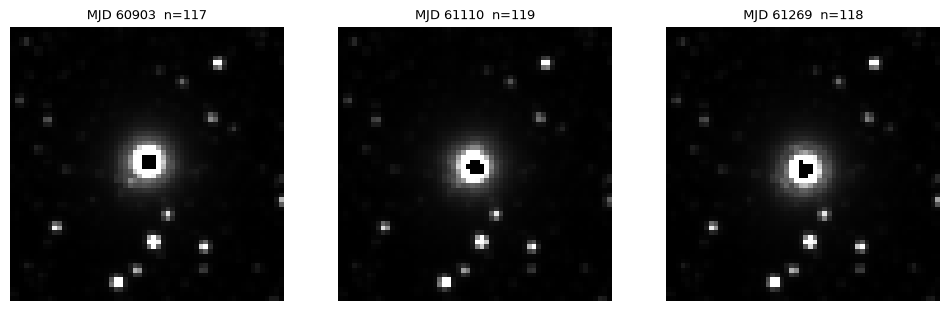

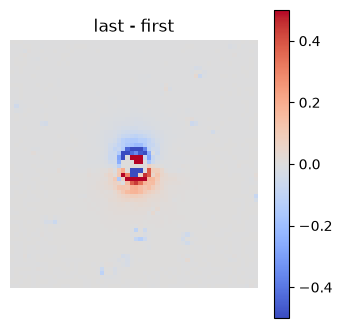

In [23]:
import sys
from pathlib import Path

# Make the repo root importable (this notebook lives in science/)
ROOT = Path.cwd().parent if Path.cwd().name == "science" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
from api.load_cache import load_cutouts
from api.targets import TARGETS
from science.pipeline import build_frames, difference

key = "barnards-star"
t = TARGETS[key]                      # ra/dec = position moved to 2026.0 by proper motion
cutouts = load_cutouts(key)           # all 383 cached cutouts, sorted by time
print(len(cutouts), "cutouts")

frames = build_frames(cutouts, t["ra"], t["dec"], fov_arcmin=6.0)
for f in frames:
    print(f"MJD {f.mjd_start:.1f}-{f.mjd_end:.1f}  n_images={f.n_images}  shape={f.image.shape}")

# time-lapse: one panel per epoch (north up, east left)
fig, axes = plt.subplots(1, len(frames), figsize=(4 * len(frames), 4))
for ax, f in zip(axes, frames):
    ax.imshow(f.image, cmap="gray", origin="upper")
    ax.set_title(f"MJD {f.mjd_start:.0f}  n={f.n_images}", fontsize=9)
    ax.axis("off")
plt.show()

# difference between the first and last epoch (later - earlier): the star's motion shows as a bright/dark pair
d = difference(frames[0], frames[-1])
plt.figure(figsize=(4, 4))
plt.imshow(d, cmap="coolwarm", origin="upper", vmin=-0.5, vmax=0.5)
plt.colorbar(); plt.title("last - first"); plt.axis("off"); plt.show()